# DS203 Project - EDA

Dataset: `DS203_final_dataset.csv` (193 countries, from `DS203_dataset_setup.ipynb`).

y: 0 = Low, 1 = Medium/High, 2 = Very High (given for this project, not an official UNDP grouping).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid")

In [ ]:
df = pd.read_csv("DS203_final_dataset.csv")
#print(df.columns)
# the WDI codes are hard to read in plots, so gave each one a short name
short_names = {
    "NY.GDP.MKTP.KD.ZG": "gdp_growth",
    "FP.CPI.TOTL.ZG": "inflation",
    "SL.UEM.TOTL.ZS": "unemployment",
    "SP.DYN.IMRT.IN": "infant_mortality",
    "EG.ELC.ACCS.ZS": "electricity",
    "IT.NET.USER.ZS": "internet",
    "NV.AGR.TOTL.ZS": "agriculture",
    "NV.IND.TOTL.ZS": "industry",
    "NE.TRD.GNFS.ZS": "trade",
}
for code_name, short in short_names.items():
    df[short] = df[code_name]
    df[short + "_year"] = df[code_name + "_year"]
    df = df.drop(columns=[code_name, code_name + "_year"])

num_cols = list(short_names.values())
class_names = ["Low", "Medium/High", "Very High"]
df["hdi_label"] = df["y"].map({0: "Low", 1: "Medium/High", 2: "Very High"})

df.head()

,country_code,hdi_2023,country,y,DominantSector,gdp_growth,gdp_growth_year,inflation,inflation_year,unemployment,...,electricity_year,internet,internet_year,agriculture,agriculture_year,industry,industry_year,trade,trade_year,hdi_label
0,AFG,0.496,Afghanistan,0.0,Services,2.266944,2023,-4.644709,2023,14.008,...,2023,15.928400,2023,34.743247,2023,13.449823,2023,66.999578,2023,Low
1,ALB,0.810,Albania,2.0,Services,4.015417,2023,4.758346,2023,10.669,...,2023,83.135592,2023,16.274239,2023,23.160712,2023,82.352493,2023,Very High
2,DZA,0.763,Algeria,1.0,Services,4.100000,2023,9.322174,2023,11.645,...,2023,76.197601,2023,13.369245,2023,37.547655,2023,43.739798,2023,Medium/High
3,AND,0.913,Andorra,2.0,Services,2.583555,2023,NaN,2021,NaN,...,2023,94.214996,2023,0.478492,2023,12.428226,2023,NaN,2021,Very High
4,AGO,0.616,Angola,1.0,Services,1.320166,2023,13.644102,2023,14.051,...,2023,37.885899,2023,20.909337,2023,35.701247,2023,53.607013,2023,Medium/High


Region isn't in the final dataset, so it is here the same way as in the setup notebook: World Bank country API, matched on ISO3 with `.map()`.

In [ ]:
import requests

resp = requests.get("https://api.worldbank.org/v2/country", params={"format": "json", "per_page": 300})
records = resp.json()[1]

region_lookup = {}
for rec in records:
    if rec["region"]["value"].strip() != "Aggregates":
        region_lookup[rec["id"]] = rec["region"]["value"].strip()

df["region"] = df["country_code"].map(region_lookup)
print("countries with no region found:", df["region"].isnull().sum())
df["region"].value_counts()

countries with no region found: 0


region
Europe & Central Asia                                51
Sub-Saharan Africa                                   48
Latin America & Caribbean                            33
East Asia & Pacific                                  30
Middle East, North Africa, Afghanistan & Pakistan    23
South Asia                                            6
North America                                         2
Name: count, dtype: int64

## 1. checking shapes and counts and datatypes

In [ ]:
print("shape:", df.shape)
print("duplicate country codes:", df["country_code"].duplicated().sum())
print(df[num_cols + ["region", "DominantSector", "y"]].dtypes)

shape: (193, 25)
duplicate country codes: 0
gdp_growth          float64
inflation           float64
unemployment        float64
infant_mortality    float64
electricity         float64
internet            float64
agriculture         float64
industry            float64
trade               float64
region                  str
DominantSector          str
y                   float64
dtype: object


In [ ]:
# summary stats for the 9 indicators
df[num_cols].describe().round(2)

,gdp_growth,inflation,unemployment,infant_mortality,electricity,internet,agriculture,industry,trade
count,189.00,178.00,179.00,191.00,193.00,182.00,186.00,186.00,170.00
mean,2.94,11.48,6.89,19.35,87.05,71.15,10.25,26.07,94.28
std,4.62,23.84,5.71,17.38,23.22,25.32,10.25,11.95,61.06
min,-29.43,-4.64,0.13,1.30,5.40,7.17,0.02,2.09,2.47
25%,1.13,3.61,3.15,5.10,85.30,58.23,2.35,18.12,51.26
50%,3.13,5.87,5.18,13.20,100.00,81.26,6.65,24.53,82.11
75%,4.94,9.33,8.50,30.05,100.00,90.84,16.79,31.56,116.39
max,33.80,221.34,34.61,71.90,100.00,100.00,43.99,78.90,402.57


             count   pct
hdi_label               
Low             26  13.5
Medium/High     93  48.2
Very High       74  38.3


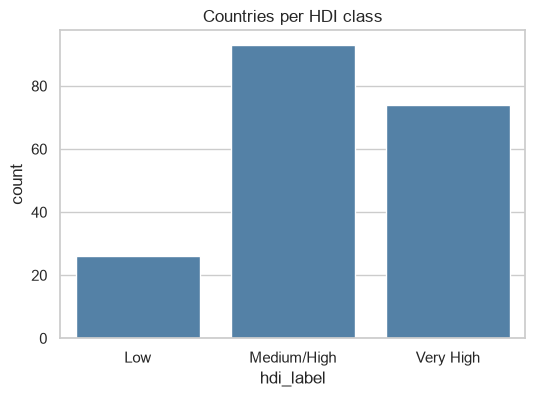

In [ ]:
class_counts = df["hdi_label"].value_counts()[class_names]
class_pct = (df["hdi_label"].value_counts() / len(df) * 100)[class_names]
print(pd.DataFrame({"count": class_counts, "pct": class_pct.round(1)}))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="hdi_label", order=class_names, color="steelblue")
plt.title("Countries per HDI class")
plt.show()

Classes aren't balanced - Low is only 26 countries (13.5%). to remember this.

## 2. Missing values

                  missing   pct
trade                  23  11.9
inflation              15   7.8
unemployment           14   7.3
internet               11   5.7
DominantSector          7   3.6
industry                7   3.6
agriculture             7   3.6
gdp_growth              4   2.1
infant_mortality        2   1.0
electricity             0   0.0
region                  0   0.0


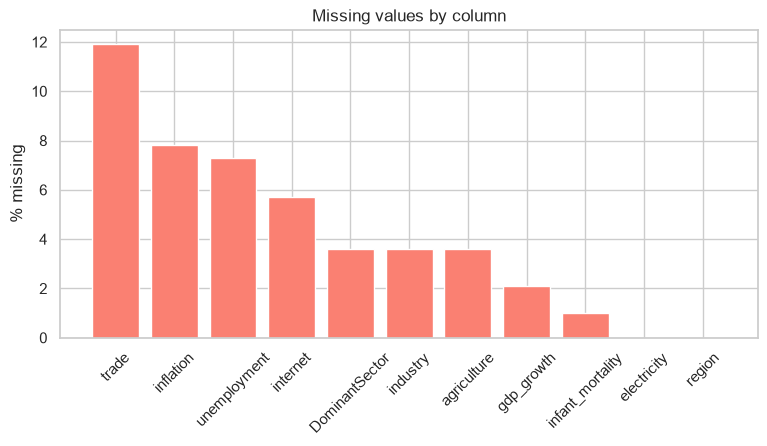

In [ ]:
miss_count = df[num_cols + ["DominantSector", "region"]].isnull().sum()
miss_pct = (miss_count / len(df) * 100).round(1)
missing_table = pd.DataFrame({"missing": miss_count, "pct": miss_pct}).sort_values("pct", ascending=False)
print(missing_table)

plt.figure(figsize=(9, 4))
plt.bar(missing_table.index, missing_table["pct"], color="salmon")
plt.xticks(rotation=45)
plt.ylabel("% missing")
plt.title("Missing values by column")
plt.show()

In [ ]:
# missing % per column, inside each class - done with a loop instead of chaining groupby on isnull
cols_to_check = num_cols + ["DominantSector"]
rows = {}
for label in class_names:
    subset = df.loc[df["hdi_label"] == label, cols_to_check]
    rows[label] = subset.isnull().mean() * 100

missing_by_class = pd.DataFrame(rows).T  # rows = class, columns = feature
missing_by_class

,gdp_growth,inflation,unemployment,infant_mortality,electricity,internet,agriculture,industry,trade,DominantSector
Low,11.538462,15.384615,0.000000,0.000000,0.0,19.230769,15.384615,15.384615,19.230769,15.384615
Medium/High,0.000000,9.677419,8.602151,0.000000,0.0,6.451613,3.225806,3.225806,13.978495,3.225806
Very High,1.351351,2.702703,8.108108,2.702703,0.0,0.000000,0.000000,0.000000,6.756757,0.000000


Trade has the most gaps overall, then inflation and unemployment. Electricity and region have none.
Low countries have more missing values than Very High ones for most columns - not random.

## 3. Distributions

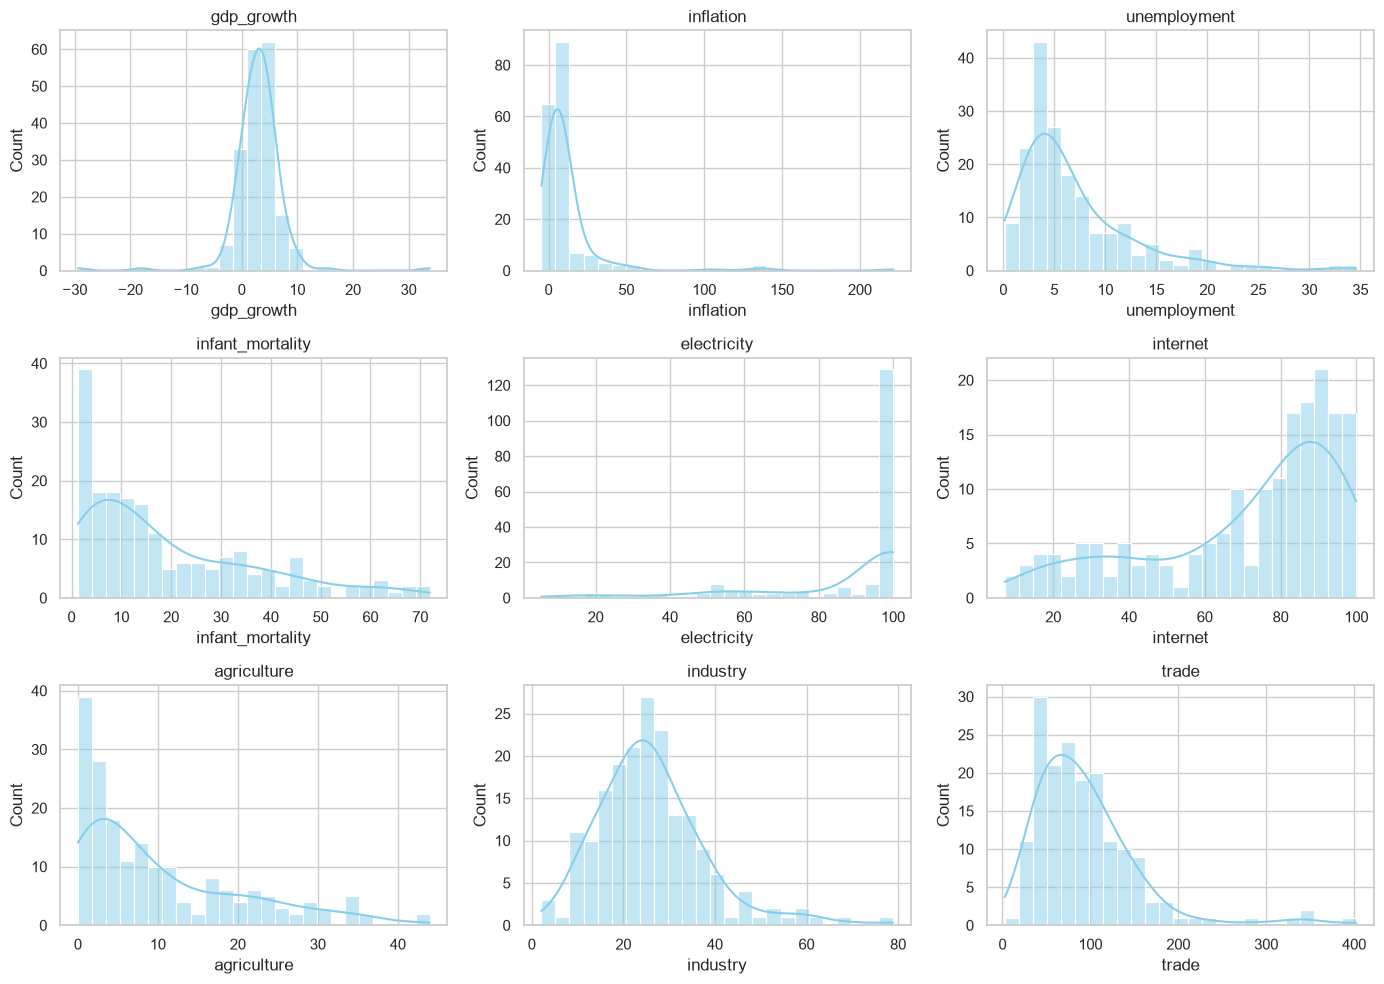

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
k = 0
for r in range(3):
    for c in range(3):
        col = num_cols[k]
        sns.histplot(df[col].dropna(), kde=True, bins=25, color="skyblue", ax=axes[r][c])
        axes[r][c].set_title(col)
        k = k + 1

plt.tight_layout()
plt.show()

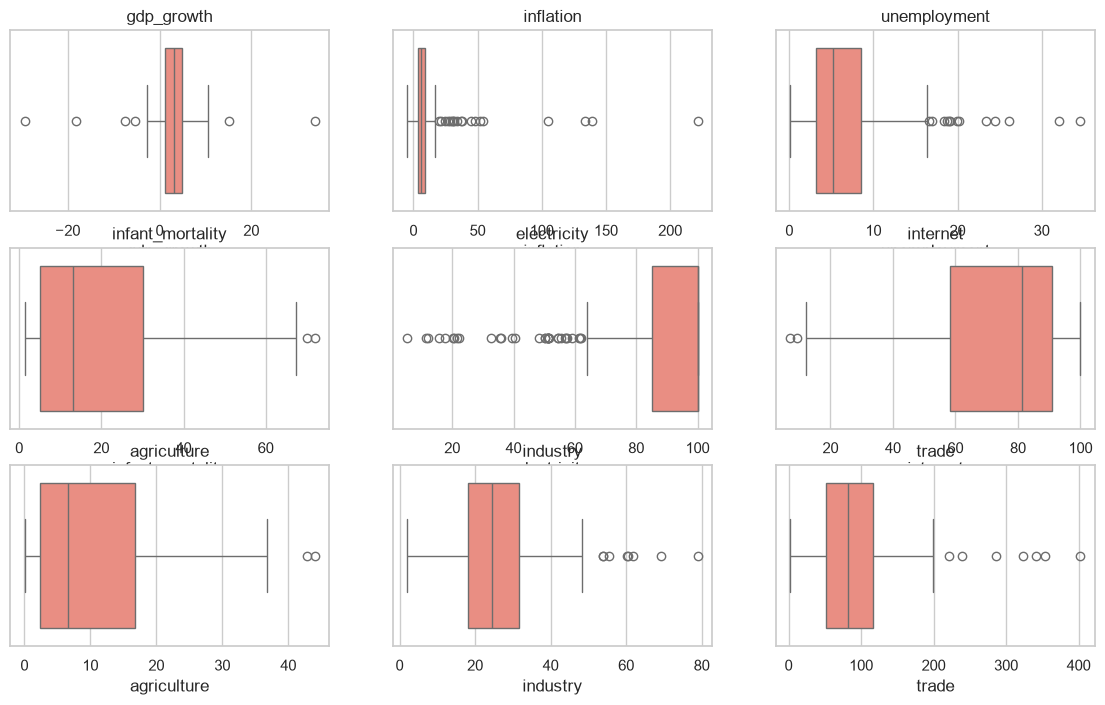

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 8))
k = 0
for r in range(3):
    for c in range(3):
        col = num_cols[k]
        sns.boxplot(x=df[col], color="salmon", ax=axes[r][c])
        axes[r][c].set_title(col)
        k = k + 1

plt.show()

Inflation, trade and unemployment have long right tails (most countries low, a few very high).
Electricity and internet are the other way - most countries bunched near 100%.

## 4. Outliers

In [ ]:
# IQR rule
for col in num_cols:
    data = df[col]
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    print(f"{col} - Q1: {Q1:.2f}, Q3: {Q3:.2f}, IQR: {IQR:.2f}, outliers: {len(outliers)}")

gdp_growth - Q1: 1.13, Q3: 4.94, IQR: 3.81, outliers: 6
inflation - Q1: 3.61, Q3: 9.33, IQR: 5.72, outliers: 19
unemployment - Q1: 3.15, Q3: 8.50, IQR: 5.35, outliers: 13
infant_mortality - Q1: 5.10, Q3: 30.05, IQR: 24.95, outliers: 2
electricity - Q1: 85.30, Q3: 100.00, IQR: 14.70, outliers: 33
internet - Q1: 58.23, Q3: 90.84, IQR: 32.62, outliers: 2
agriculture - Q1: 2.35, Q3: 16.79, IQR: 14.44, outliers: 2
industry - Q1: 18.12, Q3: 31.56, IQR: 13.43, outliers: 8
trade - Q1: 51.26, Q3: 116.39, IQR: 65.13, outliers: 7


In [ ]:
# z-score test, |z| > 3
for col in num_cols:
    temp = df.dropna(subset=[col]).copy()
    temp[col + "_zscore"] = stats.zscore(temp[col])
    extreme = temp[temp[col + "_zscore"].abs() > 3]
    print(col, "->", list(extreme["country"]))
    #print(extreme[[col, col+"_zscore"]])

gdp_growth -> ['Guyana', 'Sudan', 'Timor-Leste']
inflation -> ['Argentina', 'Lebanon', 'Sudan', 'Zimbabwe']
unemployment -> ['Djibouti', 'Eswatini', 'South Africa', 'West Bank and Gaza']
infant_mortality -> ['South Sudan']
electricity -> ['Burundi', 'Chad', 'Malawi', 'South Sudan']
internet -> []
agriculture -> ['Niger', 'Syrian Arab Republic']
industry -> ['Guyana', 'Libya']
trade -> ['Djibouti', 'Hong Kong SAR, China', 'Luxembourg', 'San Marino', 'Singapore']


In [ ]:
# sanity check: percentage columns should stay between 0 and 100
pct_cols = ["unemployment", "electricity", "internet", "agriculture", "industry"]
for col in pct_cols:
    bad = df[(df[col] < 0) | (df[col] > 100)]
    print(col, "- out of range:", len(bad))

services = 100 - df["agriculture"] - df["industry"]
print("negative services share:", (services < 0).sum())

print("countries with negative inflation (deflation):")
print(df.loc[df["inflation"] < 0, ["country", "inflation"]])

unemployment - out of range: 0
electricity - out of range: 0
internet - out of range: 0
agriculture - out of range: 0
industry - out of range: 0
negative services share: 0
countries with negative inflation (deflation):
         country  inflation
0    Afghanistan  -4.644709
149   Seychelles  -1.035301


Nothing out of range. The IQR "outliers" for electricity are just countries with low access, not errors -
these are kept, not removed.

## 5. Indicators by HDI class

In [ ]:
df.groupby("hdi_label")[num_cols].median().loc[class_names].T

hdi_label,Low,Medium/High,Very High
gdp_growth,4.257431,3.524304,1.953086
inflation,7.465975,6.026635,5.033869
unemployment,4.739000,5.407000,5.224000
infant_mortality,45.700000,17.700000,4.000000
electricity,45.400000,99.300000,100.000000
internet,23.713600,69.555801,92.216438
agriculture,28.961000,10.260457,2.131456
industry,22.210355,26.307800,23.694701
trade,55.286797,74.956267,107.277802


In [ ]:
main_cols = ["infant_mortality", "electricity", "internet", "agriculture"]
df.groupby("hdi_label")[main_cols].agg(["mean", "std"]).loc[class_names].T

hdi_label                    Low  Medium/High  Very High
infant_mortality mean  48.330769    22.259140   5.138889
                 std   12.492710    12.976678   3.452844
electricity      mean  44.980769    88.563441  99.941892
                 std   25.144399    17.818986   0.378174
internet         mean  26.952057    65.315652  90.560708
                 std   15.056281    20.413520   7.187633
agriculture      mean  27.296654    12.368123   2.595821
                 std    9.354818     8.208363   2.516206

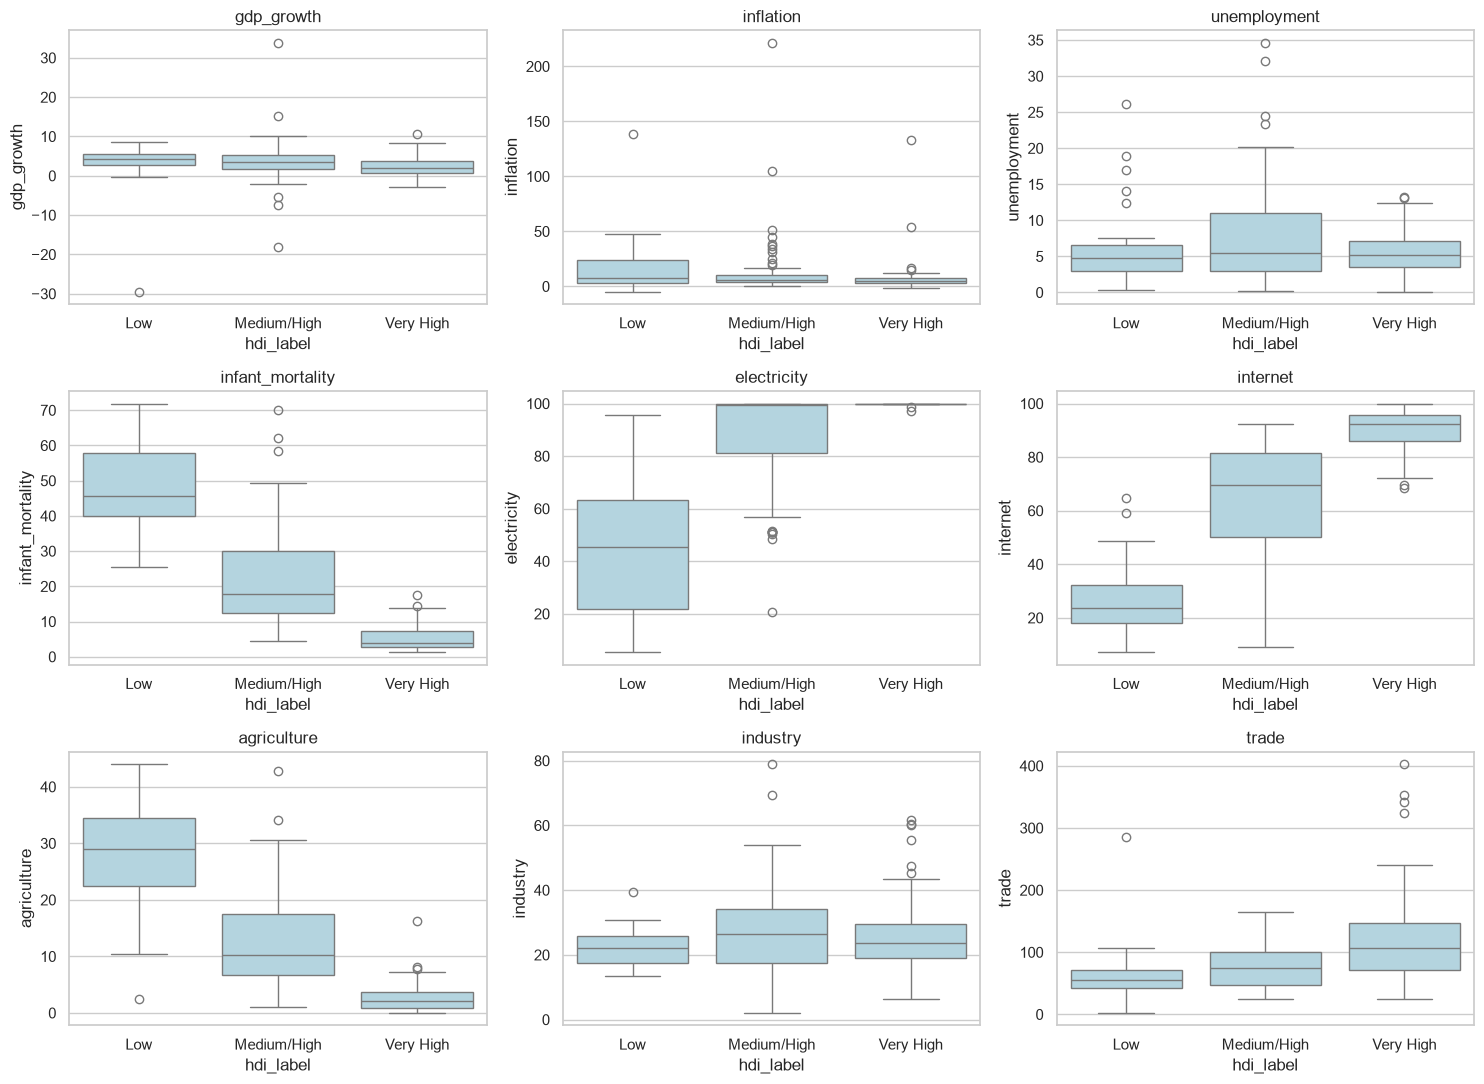

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
k = 0
for r in range(3):
    for c in range(3):
        col = num_cols[k]
        sns.boxplot(x="hdi_label", y=col, data=df, order=class_names, color="lightblue", ax=axes[r][c])
        axes[r][c].set_title(col)
        k = k + 1
plt.tight_layout()
plt.show()

Infant mortality, electricity, internet and agriculture share separate the classes the best.
GDP growth and unemployment look about the same across classes - probably not very useful alone.

## 6. Correlation between predictors

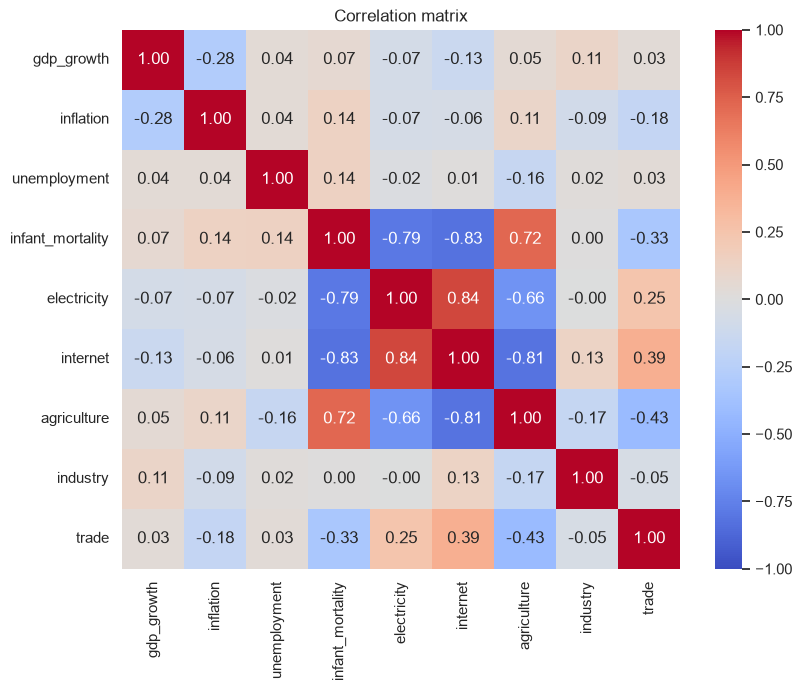

In [ ]:
corr_matrix = df[num_cols].corr(method="pearson")

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

In [ ]:
# pairs with |r| > 0.6
for i in range(len(num_cols)):
    for j in range(i + 1, len(num_cols)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.6:
            print(num_cols[i], "&", num_cols[j], "-> r =", round(r, 2))

infant_mortality & electricity -> r = -0.79
infant_mortality & internet -> r = -0.83
infant_mortality & agriculture -> r = 0.72
electricity & internet -> r = 0.84
electricity & agriculture -> r = -0.66
internet & agriculture -> r = -0.81


Infant mortality, electricity, internet and agriculture move together strongly - makes sense,
they're all roughly measuring the same "level of development" thing.

## 7. Categorical features

In [ ]:
df["DominantSector_filled"] = df["DominantSector"].fillna("Missing")

for col in ["region", "DominantSector_filled"]:
    print(df[col].value_counts())
    print()

region
Europe & Central Asia                                51
Sub-Saharan Africa                                   48
Latin America & Caribbean                            33
East Asia & Pacific                                  30
Middle East, North Africa, Afghanistan & Pakistan    23
South Asia                                            6
North America                                         2
Name: count, dtype: int64

DominantSector_filled
Services       176
Industry         8
Missing          7
Agriculture      2
Name: count, dtype: int64



In [ ]:
print(pd.crosstab(df["region"], df["hdi_label"])[class_names])
print()
print(pd.crosstab(df["DominantSector_filled"], df["hdi_label"])[class_names])

hdi_label                                          Low  Medium/High  Very High
region                                                                        
East Asia & Pacific                                  0           22          8
Europe & Central Asia                                0            7         44
Latin America & Caribbean                            0           23         10
Middle East, North Africa, Afghanistan & Pakistan    4           11          8
North America                                        0            0          2
South Asia                                           0            6          0
Sub-Saharan Africa                                  22           24          2

hdi_label              Low  Medium/High  Very High
DominantSector_filled                             
Agriculture              2            0          0
Industry                 0            4          4
Missing                  4            3          0
Services                20       

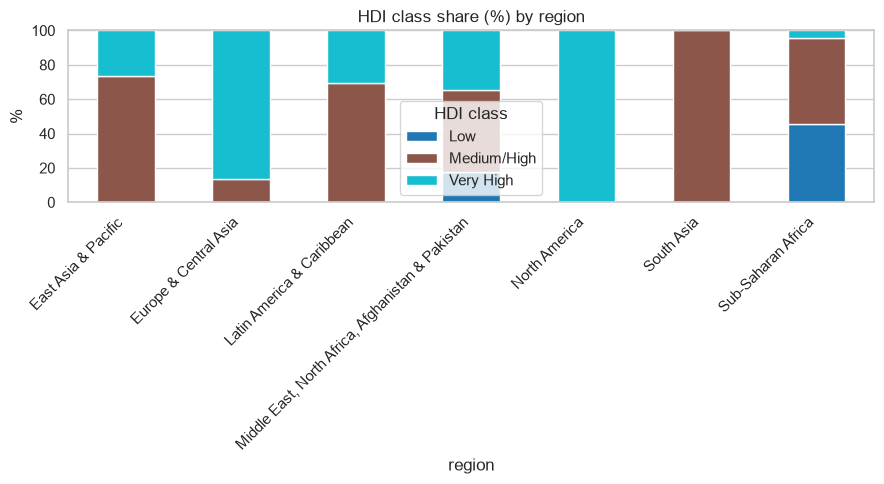

In [ ]:
ct_region = pd.crosstab(df["region"], df["hdi_label"], normalize="index") * 100
ct_region = ct_region[class_names]
ct_region.plot(kind="bar", stacked=True, colormap="tab10", figsize=(9, 5))
plt.title("HDI class share (%) by region")
plt.ylabel("%")
plt.xticks(rotation=45, ha="right")
plt.legend(title="HDI class")
plt.tight_layout()
plt.show()

Region is strongly tied to class - most Low countries are in Sub-Saharan Africa, most Europe & Central Asia
countries are Very High. DominantSector is mostly "Services" (176/193) so it won't add much on its own.

## 8. Missingness vs class

In [ ]:
df["n_missing"] = df[num_cols].isnull().sum(axis=1)

for label in class_names:
    subset = df.loc[df["hdi_label"] == label, "n_missing"]
    pct_with_gap = (subset > 0).sum() / len(subset) * 100
    print(label, "- avg missing:", round(subset.mean(), 2), " % with at least 1 gap:", round(pct_with_gap, 1))

Low - avg missing: 0.96  % with at least 1 gap: 34.6
Medium/High - avg missing: 0.45  % with at least 1 gap: 26.9
Very High - avg missing: 0.22  % with at least 1 gap: 12.2


In [ ]:
# countries with 3+ missing indicators
df.loc[df["n_missing"] >= 3, ["country", "hdi_label", "n_missing"]].sort_values("n_missing", ascending=False)

,country,hdi_label,n_missing
54,Eritrea,Low,6
190,"Yemen, Rep.",Low,6
178,Tuvalu,Medium/High,6
99,Liechtenstein,Very High,5
157,South Sudan,Low,5
120,Naoero,Medium/High,4
3,Andorra,Very High,3
118,Myanmar,Medium/High,3
155,"Somalia, Fed. Rep.",Low,3
187,"Venezuela, RB",Medium/High,3


Low countries are missing more data on average than Very High ones - missingness itself carries
a bit of signal about the class. Worth keeping in mind for preprocessing (missing-value flags).